In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Diabetes_prediction.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [4]:
print("Shape:", df.shape)
df.dtypes

Shape: (1000, 9)


Pregnancies                   int64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                         float64
Diagnosis                     int64
dtype: object

In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Diagnosis                   0
dtype: int64

In [6]:
feature_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
X = df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling applied using StandardScaler")
print("Scaled data shape:", X_scaled.shape)

Feature scaling applied using StandardScaler
Scaled data shape: (1000, 8)


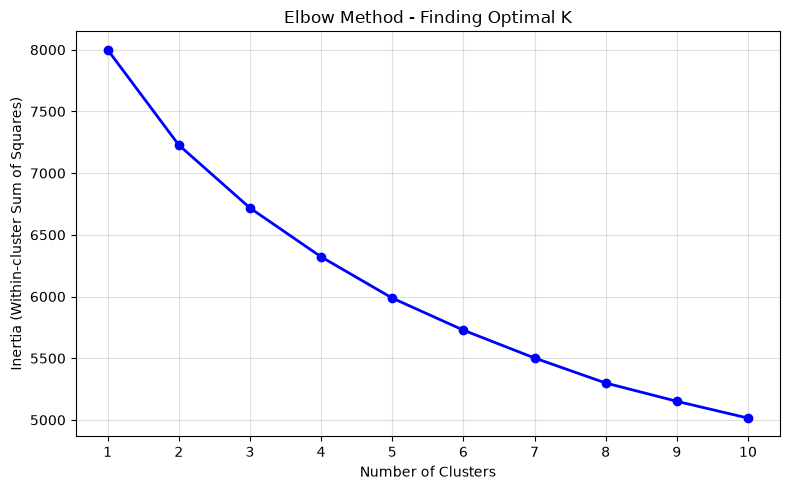

In [7]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_range), inertia, marker="o", color="blue", linewidth=2)
plt.title("Elbow Method - Finding Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia (Within-cluster Sum of Squares)")
plt.xticks(list(K_range))
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

K=2  Silhouette Score: 0.0962
K=3  Silhouette Score: 0.0866
K=4  Silhouette Score: 0.0888
K=5  Silhouette Score: 0.0901
K=6  Silhouette Score: 0.0913
K=7  Silhouette Score: 0.0924
K=8  Silhouette Score: 0.0927
K=9  Silhouette Score: 0.0951
K=10  Silhouette Score: 0.0948


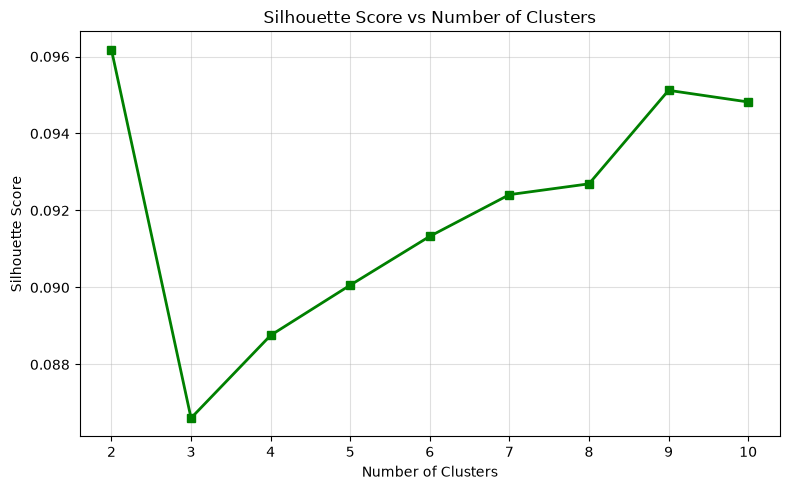

In [8]:
silhouette_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K={k}  Silhouette Score: {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="s", color="green", linewidth=2)
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [9]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_scaled)
df["Cluster"] = kmeans.labels_

print("Clustering complete (K=2)")
print("\nCluster counts:")
print(df["Cluster"].value_counts())

Clustering complete (K=2)

Cluster counts:
Cluster
1    517
0    483
Name: count, dtype: int64


In [10]:
print("Cluster vs Actual Diagnosis:")
print(df.groupby(["Cluster", "Diagnosis"]).size().unstack(fill_value=0))

Cluster vs Actual Diagnosis:
Diagnosis    0    1
Cluster            
0          331  152
1          363  154


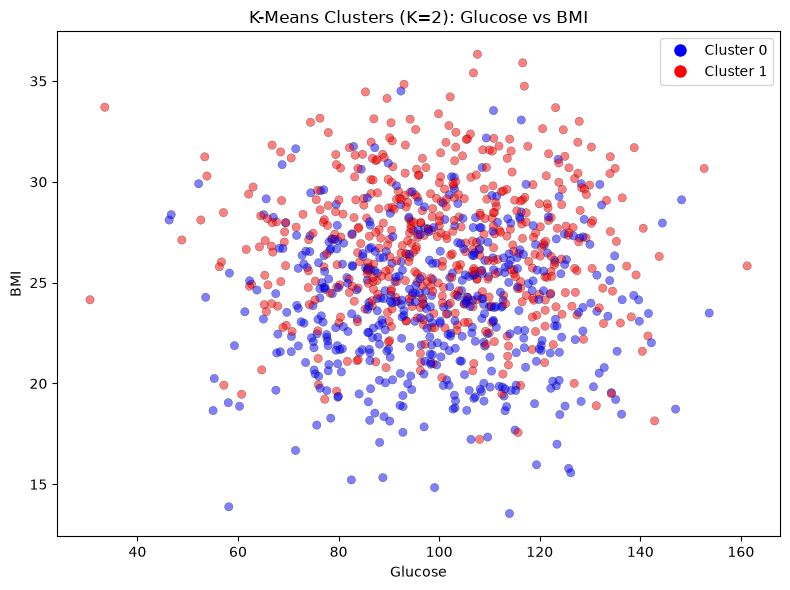

In [11]:
colors = ["blue" if c == 0 else "red" for c in df["Cluster"]]
plt.figure(figsize=(8, 6))
plt.scatter(df["Glucose"], df["BMI"], c=colors, alpha=0.5, edgecolors="k", linewidths=0.3)
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.title("K-Means Clusters (K=2): Glucose vs BMI")
plt.legend(handles=[
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="blue", markersize=10, label="Cluster 0"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="red",  markersize=10, label="Cluster 1")
])
plt.tight_layout()
plt.show()

In [12]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)
center_df = pd.DataFrame(centers, columns=feature_cols)
center_df.index.name = "Cluster"
print("Cluster Centers (original scale):")
print(center_df.round(2))

Cluster Centers (original scale):
         Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  \
Cluster                                                                       
0               1.66    98.65          71.87          22.72    72.25  23.89   
1               1.87   100.18          72.47          23.80    96.10  26.87   

         DiabetesPedigreeFunction    Age  
Cluster                                   
0                            0.57  45.18  
1                            0.34  41.51  
